In [1]:
import pandas as pd
from io import StringIO

csv_data = """spk,ly,lcr,lcb,hy,hcr,hcb,lh,ls,lv,hh,hs,hv,lr,lg,lb,hr,hg,hb,inm_th,tht_th
01,0,151,119,255,255,255,105,0,0,179,255,255,0,0,255,255,255,255,0,0
02,0,145,119,255,255,255,105,0,0,179,255,255,0,0,255,255,255,255,0,0
03,0,150,117,255,255,255,0,93,0,179,255,255,0,0,255,255,255,255,0,0
04,0,142,120,163,255,255,70,0,0,179,255,255,0,0,255,255,255,255,0,0
05,0,146,124,241,255,255,120,0,98,179,255,255,0,0,255,255,255,255,0,0
06,0,148,115,255,255,255,120,0,98,179,255,255,0,0,255,255,255,255,0,0
07,26,139,124,172,255,255,127,0,98,179,255,255,0,0,255,255,255,255,0,0
08,0,143,122,255,255,255,127,0,98,179,255,255,0,0,255,255,255,255,0,0
09,0,142,130,255,255,255,79,48,0,179,255,255,0,0,255,255,255,255,0,0
10,0,155,0,126,255,255,0,122,0,179,255,255,0,0,255,255,255,255,0,0
11,0,140,122,195,255,255,85,0,0,179,255,255,0,0,255,255,255,255,0,0
12,24,140,117,222,255,255,59,0,0,179,255,255,0,0,255,255,255,255,0,0
13,60,143,123,255,255,255,59,64,98,179,255,255,0,0,255,255,255,255,0,0
14,0,0,123,255,255,255,84,0,0,179,255,255,0,0,255,255,255,255,0,0
15,0,0,123,255,255,255,84,0,0,179,255,255,0,0,255,255,255,255,0,0
16,0,146,126,255,255,255,94,51,0,179,255,255,0,0,255,255,255,255,0,0
17,0,0,122,102,255,255,94,0,0,179,255,255,0,0,255,255,255,255,0,0
18,57,153,114,117,255,255,94,0,67,179,255,255,0,0,255,255,255,255,0,0
19,0,143,122,148,255,255,94,0,67,179,255,255,0,0,255,255,255,255,0,0
20,0,143,122,148,255,255,94,0,67,179,255,255,0,0,255,255,255,255,0,0
21,0,156,0,150,255,255,94,0,117,179,255,255,0,0,255,255,255,255,0,0
22,0,148,0,255,255,255,94,0,0,179,255,255,0,0,255,255,255,255,0,0
23,0,137,0,255,255,255,0,0,0,17,255,255,0,0,255,255,255,255,0,0
24,17,146,124,255,255,255,107,98,50,179,255,255,0,0,255,255,255,255,0,0
25,2,146,0,255,255,255,0,0,0,9,255,255,0,0,255,255,255,255,0,0
26,0,154,117,148,255,255,122,0,0,179,255,255,0,0,255,255,255,255,0,0
27,0,130,119,255,255,255,122,0,0,179,255,255,0,0,255,255,255,255,0,0
28,0,143,0,255,255,255,122,0,0,179,255,255,0,0,255,255,255,255,0,0
29,64,140,0,255,255,255,117,31,86,179,255,255,0,0,255,255,255,255,0,0
30,0,148,0,255,255,255,117,45,88,179,255,255,0,0,255,255,255,255,0,0
"""

speaker_df = pd.read_csv(StringIO(csv_data))

In [12]:
import sys
!{sys.executable} -m pip install opencv-python

  Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl (72.9 MB)

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /home/vlada/faks/mu/bin/python -m pip install --upgrade pip


In [13]:
'''feature extracor'''
import os
import math
import numpy as np
import pandas as pd
import cv2 as cv

ly = lcr = lcb = 0
hy = hcr = hcb = 0

lh = ls = lv = 0
hh = hs = hv = 0

lr = lg = lb = 0
hr = hg = hb = 0

#inner mouth mask, teeth mask
inm_mask = tht_mask = 0

kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5,5))
clahe_ycrcb = cv.createCLAHE(clipLimit=1.0, tileGridSize=(3,3))
clahe_hsv = cv.createCLAHE(clipLimit=2.0, tileGridSize=(3,3))

VIDEO_DIR = "./iseckane_reci_masked/videos/"
ROI_DIR = "./iseckane_reci_masked/roi/"

def create_hull(contour):
    return cv.convexHull(contour)

def clean_mask(mask):
    mask = cv.morphologyEx(mask, cv.MORPH_OPEN, kernel)
    mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, kernel)

    return mask

def set_values(row):
    global ly, lcr, lcb, hy, hcr, hcb
    global lh, ls, lv, hh, hs, hv
    global lr, lg, lb, hr, hg, hb
    global inm_mask, tht_mask

    ly = row['ly']
    lcr = row['lcr']
    lcb = row['lcb']
    hy = row['hy']
    hcr = row['hcr']
    hcb = row['hcb']

    lh = row['lh']
    ls = row['ls']
    lv = row['lv']
    hh = row['hh']
    hs = row['hs']
    hv = row['hv']

    lr = row['lr']
    lg = row['lg']
    lb = row['lb']
    hr = row['hr']
    hg = row['hg']
    hb = row['hb']

    inm_mask = row['inm_th']
    tht_mask = row['tht_th']

def get_ycrcb_mask(frame: MatLike):
    global ly, lcr, lcb, hy, hcr, hcb

    l_range = np.array([ly, lcr, lcb])
    h_range = np.array([hy, hcr, hcb])

    return cv.inRange(frame, l_range, h_range)

def get_hsv_mask(frame: MatLike):
    global lh, ls, lv, hh, hs, hv

    l_range = np.array([lh, ls, lv])
    h_range = np.array([hh, hs, hv])

    return cv.inRange(frame, l_range, h_range)

def get_rgb_mask(frame: MatLike):
    global lr, lg, lb, hr, hg, hb

    l_range = np.array([lr, lb, lg])
    h_range = np.array([hr, hb, hg])

    return cv.inRange(frame, l_range, h_range)

#kombinacija maske za unutransjost usta i zube
def get_inner_mouth_mask(frame):
    global inm_mask, tht_mask

    _, inner_mouth_mask = cv.threshold(frame, inm_mask, 255, cv.THRESH_BINARY_INV)
    _, teeth_mask = cv.threshold(frame, tht_mask, 255, cv.THRESH_BINARY)

    return cv.bitwise_or(inner_mouth_mask, teeth_mask)

def get_dct_features(frame, mask):
    grayscale = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    grayscale[mask == 0] = 0

    grayscale = cv.resize(grayscale, (32, 16)).astype(float)

    lip_pixels = grayscale[grayscale > 0]
    if len(lip_pixels) > 0:
        grayscale -= lip_pixels.mean()

    dct = dctn(grayscale, norm='ortho').flatten()
    dct[0] = 0

    return {f"dct_{i}": dct[i] for i in range(128)}


def process_frame(frame_crop, rectangle, roi_w, roi_h):
    y_crop = cv.cvtColor(frame_crop, cv.COLOR_BGR2YCrCb)
    hsv_crop = cv.cvtColor(frame_crop, cv.COLOR_BGR2HSV)
    rgb_crop = cv.cvtColor(frame_crop, cv.COLOR_BGR2RGB)
    grayscale = cv.cvtColor(frame_crop, cv.COLOR_BGR2GRAY)

    y_crop = cv.medianBlur(y_crop, 3)
    hsv_crop = cv.medianBlur(hsv_crop, 3)
    rgb_crop = cv.medianBlur(rgb_crop, 3)
    grayscale = cv.medianBlur(grayscale, 3)

    y_mask = get_ycrcb_mask(y_crop)
    y_mask = clean_mask(y_mask)
    y_mask = cv.bitwise_and(rectangle, y_mask)

    hsv_mask = get_hsv_mask(hsv_crop)
    hsv_mask = clean_mask(hsv_mask)
    hsv_mask = cv.bitwise_and(hsv_mask, rectangle)

    rgb_mask = get_rgb_mask(rgb_crop)
    rgb_mask = clean_mask(rgb_mask)
    rgb_mask = cv.bitwise_and(rgb_mask, rectangle)

    inner_mouth_mask = get_inner_mouth_mask(grayscale)
    inner_mouth_mask = clean_mask(inner_mouth_mask)

    lip_mask = cv.bitwise_or(y_mask, hsv_mask)
    lip_mask = cv.bitwise_or(lip_mask, rgb_mask)

    lip_region_mask = np.zeros_like(lip_mask)
    c, _ = cv.findContours(lip_mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    if not c:
        return
    
    largest = max(c, key=cv.contourArea)
    area_threshold = 0.1*cv.contourArea(largest)
    valid = [cs for cs in c if cv.contourArea(cs) >= area_threshold]

    cntr = np.vstack(valid)
    hull = create_hull(cntr)
    lip_region_mask = cv.drawContours(lip_region_mask, [hull], -1, 255, cv.FILLED)
    lip_region_mask = clean_mask(lip_region_mask)

    inner_mouth_mask = cv.bitwise_and(lip_region_mask, inner_mouth_mask)

    final_mask = cv.bitwise_or(lip_mask, inner_mouth_mask)
    final_mask = clean_mask(final_mask)

    c, _ = cv.findContours(final_mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    largest = max(c, key=cv.contourArea)
    area_threshold = 0.1*cv.contourArea(largest)
    valid = [cs for cs in c if cv.contourArea(cs) >= area_threshold]

    cntr = np.vstack(valid)
    hull = create_hull(cntr)

    points = hull.reshape(-1, 2)
    xs = points[:, 0]
    ys = points[:, 1]

    left_x = np.min(xs)
    right_x = np.max(xs)

    left_y = np.mean(ys[xs == left_x])
    right_y = np.mean(ys[xs == right_x])

    top_y = np.min(ys)
    bottom_y = np.max(ys)

    width = right_x - left_x
    height = bottom_y - top_y

    hull_area = cv.contourArea(hull)

    aspect_ratio = width/height if height > 0 else 0

    angle = np.degrees(np.arctan2(
            right_y - left_y,
            right_x - left_x
        ))

    (cx, cy), (MA, ma), ellipse_angle = cv.fitEllipse(hull)
    ellipse_area = math.pi / 4 * MA * ma

    M = cv.moments(hull)
    cy = M['m01'] / M['m00']
    
    upper_height = (cy - top_y) / height
    lower_height = (bottom_y - cy) / height

    obim = cv.arcLength(hull, True)
    okruglost = (4 * math.pi * hull_area) / (obim ** 2)

    feature_dict = {
            "width": width / roi_w,
            "height": height / roi_h,
            "hull_area": hull_area / (width ** 2),
            "aspect_ratio": aspect_ratio,
            "angle": angle,
            "ellipse_area": ellipse_area / (width ** 2),
            "solidity" : ellipse_area / hull_area,
            "upper_lip_height": upper_height,
            "lower_lip_height": lower_height,
            "circularity": okruglost,
            
            #ovo je samo ako mi kasnije bude bilo potrebno da izvlacim 
            #nesto iz cistog videa
            "raw_height": height,
            "raw_width": width,
            "x": left_x,
            "y": top_y
            }
    
    #y = top_y
    #x = left_x
    #for_dct = frame_crop[y:y+int(height), x:x+int(width)]
    #mask_for_dct = final_mask[y:y+int(height), x:x+int(width)]
    #dct_features = get_dct_features(for_dct, mask_for_dct)
    return feature_dict

def process_video(video_path, roi_path):
    video = cv.VideoCapture(video_path)
    roi = pd.read_csv(roi_path)

    idx = 0
    feature_frame_list = []
    while video.isOpened():
        ret, frame = video.read()
        if not ret:
            break

        row = roi.iloc[idx]
        roi_x, roi_y, roi_w, roi_h = \
        int(row['x']), int(row['y']), int(row['width']), int(row['height'])
        
        frame_crop = frame[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w]
        frame_crop = cv.medianBlur(frame_crop, 3)
            
        idx += 1

        grayscale = cv.cvtColor(frame_crop, cv.COLOR_BGR2GRAY)
        start_x = int(0.15*roi_w)
        start_y = int(0.15*roi_h)
        end_x = roi_w - int(0.15*roi_w)
        end_y = roi_h - int(0.15*roi_h)
        rectangle_mask = cv.rectangle(
                np.zeros_like(grayscale),
                (start_x, start_y),
                (end_x, end_y),
                (255, 255, 255),
                cv.FILLED)
        
        features = process_frame(frame_crop, rectangle_mask, roi_w, roi_h)
        feature_frame_list.append(features)

    video.release()
    df = pd.DataFrame(feature_frame_list)
    return df

speaker_idx = 0

videos = sorted(os.listdir(VIDEO_DIR))
for video in videos:
    #print(video)
    row = speaker_df.iloc[speaker_idx // 30]
    set_values(row)

    roi = video.replace(".mp4", ".txt")

    video_path = os.path.join(VIDEO_DIR, video)
    roi_path = os.path.join(ROI_DIR, roi)

    df = process_video(video_path, roi_path)

    csv = video.replace(".mp4", ".csv")
    df.to_csv(os.path.join("./per_frame_features/", csv))

    speaker_idx += 1

In [14]:
import os
import pandas as pd
import numpy as np

geometric_features = [
        "width",
        "height",
        "hull_area",
        "aspect_ratio",
        "angle",
        "ellipse_area",
        "solidity",
        "upper_lip_height",
        "lower_lip_height",
        "circularity"
        ]

d_geometric_features = [
        "d_height",
        "d_area",
        "d_aspect_ratio",
        "d_angle",
        "d_ellipse_ratio",
        "d_corner_height_diff",
        "d_upper_lip_height",
        "d_lower_lip_height"
        ]

N_TIMESTEPS = 10

test_speakers = [4, 8, 14, 26, 28]

def agregate(df, feature):
    name_mean = feature + "_mean"
    name_std = feature + "_std"
    name_max = feature + "_max"
    name_min = feature + "_min"

    ret = {
            name_mean: df[feature].mean(),
            name_std: df[feature].std(),
            name_max: df[feature].max(),
            name_min: df[feature].min()
    }
    
    return ret

def temporal_agregate(df, feature):
    name_mean = "d_" + feature + "_mean"
    name_std =  "d_" + feature + "_std"
    name_max =  "d_" + feature + "_max"
    name_min =  "d_" + feature + "_min"

    ret = {
            name_mean: df[feature].mean(),
            name_std: df[feature].std(),
            name_max: df[feature].max(),
            name_min: df[feature].min()
    }
    
    return ret

def interpolate(df, feature):
    f_old = df[feature]
    x_old = np.linspace(0, 1, len(df))
    x_new = np.linspace(0, 1, N_TIMESTEPS)

    f_new = np.interp(x_new, x_old, f_old)

    ret = {}
    i = 0
    for f_val in f_new:
        name = feature + "_t" + str(i)
        ret[name] = f_val

        i += 1

    return ret

def timed(df, feature):
    ret = {}

    name_max = feature + "_tmax"
    name_min = feature + "_tmin"

    ret[name_max] = df[feature].idxmax() / len(df)
    ret[name_min] = df[feature].idxmin() / len(df)

    return ret

def temporal_timed(df, feature):
    ret = {}

    name_max = feature + "_tmax"
    name_min = feature + "_tmin"

    ret[name_max] = df[feature].idxmax() / len(df)
    ret[name_min] = df[feature].idxmin() / len(df)

    return ret

def agregate_features(csv_path: str, label: int, spk: int):
    df = pd.read_csv(csv_path)
    d_df = df[geometric_features].diff().fillna(0)
    ret = {}

    for feature in geometric_features:
        ret.update(agregate(df, feature))
        ret.update(temporal_agregate(d_df, feature))
    
    ret["y"] = label
    ret["spk"] = spk

    return ret

def interpolate_features(csv_path: str, label: int, spk: int):
    df = pd.read_csv(csv_path)
    ret = {}

    for feature in geometric_features:
        ret.update(interpolate(df, feature))
    
    ret["y"] = label
    ret["spk"] = spk

    return ret

def time_features(csv_path: str, label: int, spk: int):
    df = pd.read_csv(csv_path)
    d_df = df[geometric_features].diff().fillna(0)
    ret = {}

    for feature in geometric_features:
        ret.update(timed(df, feature))
    
    ret["duration"] = len(df)
    ret["y"] = label
    ret["spk"] = spk

    return ret

PER_FRAME_DIR = "./per_frame_features/"

per_frame_features = sorted(os.listdir(PER_FRAME_DIR))
i = 0
X_agregated = []
X_interp = []
X_timed = []
for frame_features in per_frame_features:
    #print(frame_features)
    csv_path = os.path.join(PER_FRAME_DIR, frame_features)
    #X_agregated.append(agregate_features(csv_path, i % 30, i // 30 + 1))
    #X_interp.append(interpolate_features(csv_path, i % 30, i // 30 + 1))
    X_timed.append(time_features(csv_path, i % 30, i // 30 + 1))

    i += 1

#df = pd.DataFrame(X_agregated)
#df.to_csv('geometric_agregated.csv', index=False)

#df_interp = pd.DataFrame(X_interp)
#df_interp.to_csv('geometric_interp.csv', index=False)

df_timed = pd.DataFrame(X_timed)
df_timed.to_csv('geometric_timed.csv', index=False)

In [15]:
import os
import numpy as np
import pandas as pd
import cv2 as cv
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

CROP_SIZE = (64, 32)
N_COMPONENTS = 20
N_TIMESTEPS = 20

def show_eigenlips(pca, crop_size):
    fig, axes = plt.subplots(1, 3, figsize=(6, 2))
    for i in range(3):
        eigenlip = pca.components_[i].reshape(crop_size[1], crop_size[0])
        eigenlip = (eigenlip - eigenlip.min()) / \
                   (eigenlip.max() - eigenlip.min() + 1e-6)
        axes[i].imshow(eigenlip, cmap='gray')
        axes[i].set_title(f"PC{i+1}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

def load_frames(video_path: str, roi_path: str):
    video = cv.VideoCapture(video_path)
    roi = pd.read_csv(roi_path)

    frames = []

    idx = 0
    while video.isOpened():
        ret, frame = video.read()

        if not ret:
            break

        row = roi.iloc[idx]
        x, y, w, h = int(row['x']), int(row['y']), int(row['width']), int(row['height'])

        frame_crop = frame[y:y+h, x:x+w]
        grayscale = cv.cvtColor(frame_crop, cv.COLOR_BGR2GRAY)
        grayscale = cv.resize(grayscale, CROP_SIZE).astype(float)
        grayscale /= 255.0

        frames.append(grayscale.flatten())

        idx += 1

    video.release()
    return np.array(frames)

def get_row(pca, video_path, roi_path, label, spk):
    frames = load_frames(video_path, roi_path)
    frames = pca.transform(frames)

    ret = {}

    for i in range(N_COMPONENTS):
        f_old = frames[:, i]

        x_old = np.linspace(0, 1, len(frames))
        x_new = np.linspace(0, 1, N_TIMESTEPS)
        f_new = np.interp(x_new, x_old, f_old)

        idx = 0
        for f_val in f_new:
            name = "pca" + str(i) + "_t" + str(idx)
            ret[name] = f_val
            idx += 1

    ret["y"] = label
    ret["spk"] = spk

    return ret

VIDEO_DIR = "./iseckane_reci_masked/videos/"
ROI_DIR = "./iseckane_reci_masked/roi/"

test_speakers = [4, 8, 14, 26, 28]

videos = sorted(os.listdir(VIDEO_DIR))

train_frames = []
i = 0
for video in videos:
    video_path = os.path.join(VIDEO_DIR, video)
    roi = video.replace('.mp4', '.txt')
    roi_path = os.path.join(ROI_DIR, roi)
    
    if (i // 30 + 1) not in test_speakers:
        train_frames.append(load_frames(video_path, roi_path))

    i += 1

train_frames = np.vstack(train_frames)
pca = PCA(n_components=N_COMPONENTS, whiten=True)
pca.fit(train_frames)

#show_eigenlips(pca, CROP_SIZE)

rows = []
i = 0
for video in videos:
    video_path = os.path.join(VIDEO_DIR, video)
    roi = video.replace('.mp4', '.txt')
    roi_path = os.path.join(ROI_DIR, roi)
    
    rows.append(get_row(pca, video_path, roi_path, i % 30, i // 30 + 1))

    i += 1

df = pd.DataFrame(rows)
df.to_csv('features_pca.csv', index=False)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline


RF_PARAM_DIST = {
    "rf__n_estimators":      [300, 500],
    "rf__max_depth":         [5, 7, None],
    "rf__min_samples_split": [5, 7, 10],
    "rf__min_samples_leaf":  [4, 8],
    "rf__max_features":      ["sqrt", "log2"],
}

def print_feature_importance(rf_model, X):
    importances = rf_model.feature_importances_
    feature_names = X.columns
    
    feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
    print(feature_importance_df)

def no_pca_lda(cv):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("rf", RandomForestClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
        pipe,
        RF_PARAM_DIST,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    
    print("Samo StandardScaler")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_lda(cv):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis()),
        ("rf", RandomForestClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
        pipe,
        RF_PARAM_DIST,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    
    print("Samo LDA")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_pca(cv, n):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("rf", RandomForestClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
        pipe,
        RF_PARAM_DIST,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def pca_lda(cv, n):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("lda", LinearDiscriminantAnalysis()),
        ("rf", RandomForestClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
        pipe,
        RF_PARAM_DIST,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

test_speakers = [4, 8, 14, 26, 28]

df_timed = pd.read_csv('geometric_timed.csv')
df_timed = df_timed.drop(["y", "spk"], axis=1)

pca_df = pd.read_csv('features_pca.csv')

df = pd.concat([df_timed, pca_df], axis=1)

X_train = df.loc[~df["spk"].isin(test_speakers)]
y_train = X_train["y"]
X_train = X_train.drop(["spk", "y"], axis=1)

X_test = df.loc[df["spk"].isin(test_speakers)]
y_test = X_test["y"]
X_test = X_test.drop(["spk", "y"], axis=1)

print("X train shape", X_train.shape)
print("X test shape", X_test.shape)

print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

no_pca_lda(cv)
only_lda(cv)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    only_pca(cv, n)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    pca_lda(cv, n)

#print_feature_importance(best_rf.named_steps['rf'], X_train)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline

KNN_PARAMS = {
        "knn__n_neighbors": [5, 10, 15, 25],
        "knn__weights": ['uniform', 'distance'],
        "knn__metric": ['euclidean', 'manhattan', 'cosine'],
        }

def no_pca_lda(cv):
    pipe = Pipeline([
         ("scale", StandardScaler()),
         ("knn", KNeighborsClassifier())
    ])
    search = GridSearchCV(
            pipe,
            KNN_PARAMS,
            scoring = 'accuracy',
            n_jobs=-1,
            cv=cv
        )
    search.fit(X_train, y_train)
    
    print("\nSamo StandardScaler")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_lda(cv):
    pipe = Pipeline([
         ("scale", StandardScaler()),
         ("lda", LinearDiscriminantAnalysis()),
         ("knn", KNeighborsClassifier())
    ])
    search = GridSearchCV(
            pipe,
            KNN_PARAMS,
            scoring = 'accuracy',
            n_jobs=-1,
            cv=cv
        )
    search.fit(X_train, y_train)
    
    print("\nSamo LDA")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_pca(cv, n):
    pipe = Pipeline([
         ("scale", StandardScaler()),
         ("pca", PCA(n_components=n, whiten=True)),
         ("knn", KNeighborsClassifier())
    ])
    search = GridSearchCV(
            pipe,
            KNN_PARAMS,
            scoring = 'accuracy',
            n_jobs=-1,
            cv=cv
        )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def pca_lda(cv, n):
    pipe = Pipeline([
         ("scale", StandardScaler()),
         ("pca", PCA(n_components=n, whiten=True)),
         ("lda", LinearDiscriminantAnalysis()),
         ("knn", KNeighborsClassifier())
    ])
    search = GridSearchCV(
            pipe,
            KNN_PARAMS,
            scoring = 'accuracy',
            n_jobs=-1,
            cv=cv
        )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

test_speakers = [4, 8, 14, 26, 28]

df_timed = pd.read_csv('geometric_timed.csv')
df_timed = df_timed.drop(["y", "spk"], axis=1)

pca_df = pd.read_csv('features_pca.csv')

df = pd.concat([df_timed, pca_df], axis=1)

X_train = df.loc[~df["spk"].isin(test_speakers)]
y_train = X_train["y"]
X_train = X_train.drop(["spk", "y"], axis=1)

X_test = df.loc[df["spk"].isin(test_speakers)]
y_test = X_test["y"]
X_test = X_test.drop(["spk", "y"], axis=1)

print("X train shape", X_train.shape)
print("X test shape", X_test.shape)

print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

no_pca_lda(cv)
only_lda(cv)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    only_pca(cv, n)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    pca_lda(cv, n)

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import pandas as pd
import numpy as np
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline

MLP_PARAMS = {
        "mlp__hidden_layer_sizes" : [(128, ), (256, ), (512, )],
        "mlp__activation": ['relu', 'tanh', 'logistic'],
        "mlp__max_iter": [200, 500],
        "mlp__alpha": [0.1, 0.01, 0.001, 0.0001],
        }

def no_pca_lda(cv):
    pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("mlp", MLPClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
            pipe,
            MLP_PARAMS,
            scoring='accuracy',
            n_jobs=-1,
            cv=cv
            )
    search.fit(X_train, y_train)
    
    print("\nSamo StandardScaler")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_lda(cv):
    pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("lda", LinearDiscriminantAnalysis()),
            ("mlp", MLPClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
            pipe,
            MLP_PARAMS,
            scoring='accuracy',
            n_jobs=-1,
            cv=cv
            )
    search.fit(X_train, y_train)
    
    print("\nSamo LDA")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_pca(cv, n):
    pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n)),
            ("mlp", MLPClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
            pipe,
            MLP_PARAMS,
            scoring='accuracy',
            n_jobs=-1,
            cv=cv
            )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def pca_lda(cv, n):
    pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n)),
            ("lda", LinearDiscriminantAnalysis()),
            ("mlp", MLPClassifier(random_state=42))
        ])
    
    search = GridSearchCV(
            pipe,
            MLP_PARAMS,
            scoring='accuracy',
            n_jobs=-1,
            cv=cv
            )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

warnings.simplefilter("ignore", category=ConvergenceWarning)

test_speakers = [4, 8, 14, 26, 28]

df_timed = pd.read_csv('geometric_timed.csv')
df_timed = df_timed.drop(["y", "spk"], axis=1)

pca_df = pd.read_csv('features_pca.csv')

df = pd.concat([df_timed, pca_df], axis=1)

X_train = df.loc[~df["spk"].isin(test_speakers)]
y_train = X_train["y"]
X_train = X_train.drop(["spk", "y"], axis=1)

X_test = df.loc[df["spk"].isin(test_speakers)]
y_test = X_test["y"]
X_test = X_test.drop(["spk", "y"], axis=1)

print("X train shape", X_train.shape)
print("X test shape", X_test.shape)

print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

no_pca_lda(cv)
only_lda(cv)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    only_pca(cv, n)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    pca_lda(cv, n)

X train shape (750, 421)
X test shape (150, 421)
y train shape (750,)
y test shape (150,)

Samo StandardScaler
Best parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV accuracy: 0.2627

Train accuracy: 1.0000
Test accuracy:  0.5800

Samo LDA
Best parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV accuracy: 0.3720

Train accuracy: 1.0000
Test accuracy:  0.5200

PCA: 0.8
Best parameters: {'svm__C': 100, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV accuracy: 0.0947

Train accuracy: 0.8387
Test accuracy:  0.2800

PCA: 0.85
Best parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV accuracy: 0.2013

Train accuracy: 0.9773
Test accuracy:  0.4333

PCA: 0.9
Best parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV accuracy: 0.2600

Train accuracy: 1.0000
Test accuracy:  0.4933

PCA: 0.95
Best parameters: {'svm__C': 1.0, 'svm__gamma': 'scale', 'svm__kernel': 'li

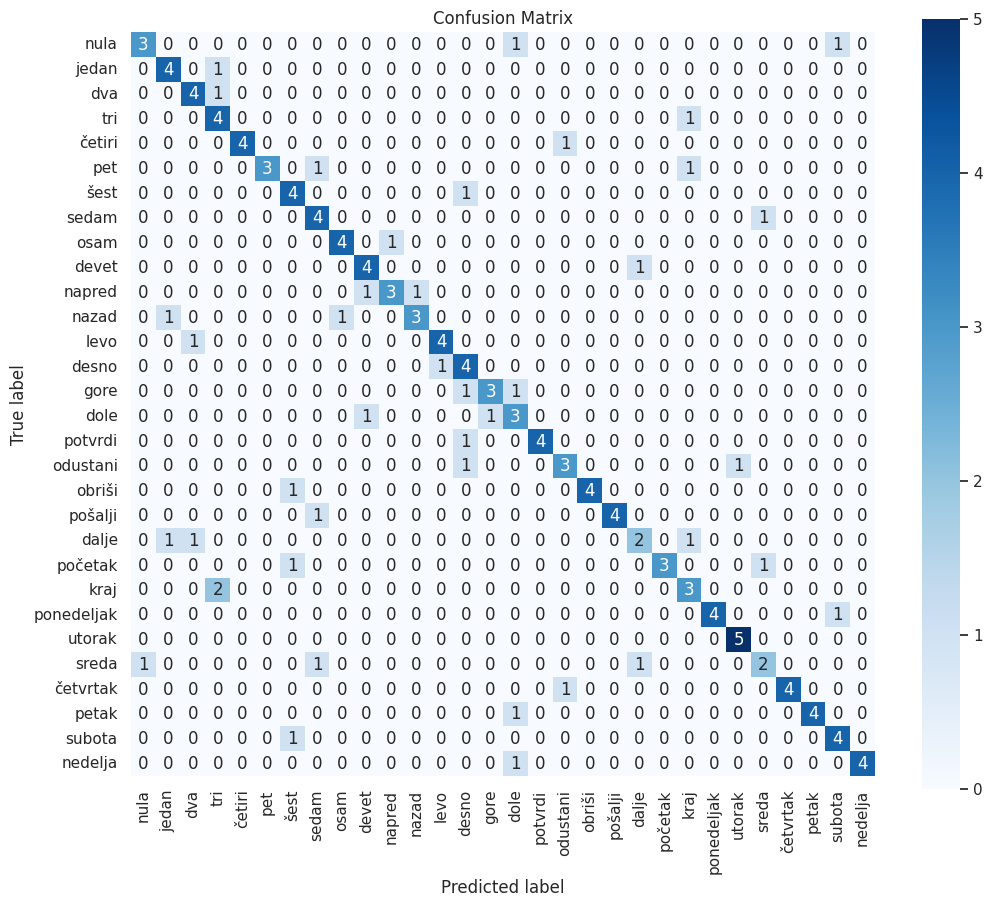

In [16]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np
import pandas as pd

SVM_PARAMS = {
        "svm__C": [0.1, 1.0, 10, 100],
        "svm__kernel": ['linear', 'rbf'],
        "svm__gamma": ['scale', 'auto', 0.1],
        }

def no_pca_lda(cv):
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC())
        ])
    
    search = GridSearchCV(
            pipe,
            SVM_PARAMS,
            scoring="accuracy",
            cv=cv,
            n_jobs=-1
        )
    search.fit(X_train, y_train)
    
    print("\nSamo StandardScaler")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_lda(cv):
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis()),
        ("svm", SVC())
        ])
    
    search = GridSearchCV(
            pipe,
            SVM_PARAMS,
            scoring="accuracy",
            cv=cv,
            n_jobs=-1
        )
    search.fit(X_train, y_train)
    
    print("\nSamo LDA")
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def only_pca(cv, n):
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=n, whiten=True)),
        ("svm", SVC())
        ])
    
    search = GridSearchCV(
            pipe,
            SVM_PARAMS,
            scoring="accuracy",
            cv=cv,
            n_jobs=-1
        )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

def pca_lda(cv, n):
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=n, whiten=True)),
        ("lda", LinearDiscriminantAnalysis()),
        ("svm", SVC())
        ])
    
    search = GridSearchCV(
            pipe,
            SVM_PARAMS,
            scoring="accuracy",
            cv=cv,
            n_jobs=-1
        )
    search.fit(X_train, y_train)
    
    print("\nPCA:", n)
    print(f"Best parameters: {search.best_params_}")
    print(f"Best CV accuracy: {search.best_score_:.4f}")
    
    best_rf = search.best_estimator_
    y_pred  = best_rf.predict(X_test)
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    test_acc  = accuracy_score(y_test, y_pred)
    
    print(f"\nTrain accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")

test_speakers = [4, 8, 14, 26, 28]

df_timed = pd.read_csv('geometric_timed.csv')
df_timed = df_timed.drop(["y", "spk"], axis=1)

pca_df = pd.read_csv('features_pca.csv')

df = pd.concat([df_timed, pca_df], axis=1)

X_train = df.loc[~df["spk"].isin(test_speakers)]
y_train = X_train["y"]
X_train = X_train.drop(["spk", "y"], axis=1)

X_test = df.loc[df["spk"].isin(test_speakers)]
y_test = X_test["y"]
X_test = X_test.drop(["spk", "y"], axis=1)

print("X train shape", X_train.shape)
print("X test shape", X_test.shape)

print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

no_pca_lda(cv)
only_lda(cv)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    only_pca(cv, n)

for n in [0.8, 0.85, 0.9, 0.95, 0.98, 0.99]:
    pca_lda(cv, n)

words = ["nula", "jedan", "dva", "tri", "četiri", "pet",
         "šest", "sedam", "osam", "devet",
         "napred", "nazad", "levo", "desno", "gore", "dole",
         "potvrdi", "odustani", "obriši", "pošalji", "dalje", "početak", "kraj",
         "ponedeljak", "utorak", "sreda", "četvrtak", "petak", "subota", "nedelja"]

pipe = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=0.98, whiten=True)),
    ("lda", LinearDiscriminantAnalysis()),
    ("svm", SVC())
    ])

search = GridSearchCV(
        pipe,
        SVM_PARAMS,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )
search.fit(X_train, y_train)
best_rf = search.best_estimator_
y_pred  = best_rf.predict(X_test)

plt.figure(figsize=(12,10))
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
             index = words, 
             columns = words)
ax = sns.heatmap(cm_df, 
                 fmt = 'd', 
                 cmap="Blues", 
                 cbar=True,  
                 annot=True,
                 square=True)

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')
plt.show()